<a href="https://colab.research.google.com/github/tanvi118/NLP_Lab/blob/main/NLP_Exp_9_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Tanvi Vitankar, 500120658, exp-9,10

 Topic:StudyGraph AI

 Description: StudyGraph AI is an NLP-based intelligent study assistant that converts unstructured study notes into structured and meaningful information. It uses techniques such as text preprocessing, TF-IDF keyword extraction, Named Entity Recognition (NER), dependency parsing, text summarization, and cosine similarity. The system automatically identifies important concepts and relationships to generate a visual knowledge graph, creates study questions, summarizes notes, and allows users to search for relevant information. The project helps students understand, organize, and revise study material efficiently without using any external APIs.

In [1]:
!pip install -q spacy networkx matplotlib scikit-learn sumy
!python -m spacy download en_core_web_sm -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
import re
import nltk
import spacy
import networkx as nx
import matplotlib.pyplot as plt

from collections import Counter
from sklearn.feature_extraction.text import TfidfVectorizer

from sumy.parsers.plaintext import PlaintextParser
from sumy.nlp.tokenizers import Tokenizer
from sumy.summarizers.lsa import LsaSummarizer

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

from nltk.corpus import stopwords
from nltk.tokenize import sent_tokenize, word_tokenize

nlp = spacy.load("en_core_web_sm")

print("StudyGraph AI libraries loaded successfully!")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


StudyGraph AI libraries loaded successfully!


In [3]:
study_text = """
Natural Language Processing is a branch of Artificial Intelligence that
allows computers to understand, interpret and generate human language.

NLP combines computational linguistics with machine learning and deep
learning techniques.

Tokenization is the process of breaking text into smaller units called tokens.
These tokens can be words, sentences or subwords.

Named Entity Recognition identifies entities such as people,
organizations, locations and dates from text.

Machine learning algorithms are widely used in NLP for text classification,
sentiment analysis and spam detection.

Deep learning models such as Recurrent Neural Networks and Transformers
have significantly improved NLP applications.

BERT is a transformer-based language model developed by Google.
It uses bidirectional contextual representations to understand language.

NLP is used in applications such as chatbots, machine translation,
question answering, text summarization and sentiment analysis.
"""

print(study_text)


Natural Language Processing is a branch of Artificial Intelligence that
allows computers to understand, interpret and generate human language.

NLP combines computational linguistics with machine learning and deep
learning techniques.

Tokenization is the process of breaking text into smaller units called tokens.
These tokens can be words, sentences or subwords.

Named Entity Recognition identifies entities such as people,
organizations, locations and dates from text.

Machine learning algorithms are widely used in NLP for text classification,
sentiment analysis and spam detection.

Deep learning models such as Recurrent Neural Networks and Transformers
have significantly improved NLP applications.

BERT is a transformer-based language model developed by Google.
It uses bidirectional contextual representations to understand language.

NLP is used in applications such as chatbots, machine translation,
question answering, text summarization and sentiment analysis.



In [4]:
def preprocess_text(text):

    doc = nlp(text)

    tokens = []

    for token in doc:

        if (
            not token.is_stop
            and not token.is_punct
            and not token.is_space
        ):
            tokens.append(token.lemma_.lower())

    return tokens


processed_tokens = preprocess_text(study_text)

print("Original number of words:", len(study_text.split()))
print("Processed tokens:", len(processed_tokens))

print("\nFirst 30 processed tokens:")
print(processed_tokens[:30])

Original number of words: 129
Processed tokens: 90

First 30 processed tokens:
['natural', 'language', 'processing', 'branch', 'artificial', 'intelligence', 'allow', 'computer', 'understand', 'interpret', 'generate', 'human', 'language', 'nlp', 'combine', 'computational', 'linguistic', 'machine', 'learning', 'deep', 'learn', 'technique', 'tokenization', 'process', 'break', 'text', 'small', 'unit', 'call', 'tokens']


In [5]:
word_frequency = Counter(processed_tokens)

top_words = word_frequency.most_common(15)

print("TOP IMPORTANT WORDS\n")

for word, frequency in top_words:
    print(f"{word:20} : {frequency}")

TOP IMPORTANT WORDS

language             : 4
nlp                  : 4
text                 : 4
machine              : 3
understand           : 2
learning             : 2
deep                 : 2
learn                : 2
entity               : 2
sentiment            : 2
analysis             : 2
model                : 2
application          : 2
natural              : 1
processing           : 1


In [6]:
def extract_keywords(text, number=10):

    sentences = sent_tokenize(text)

    vectorizer = TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2)
    )

    matrix = vectorizer.fit_transform(sentences)

    scores = matrix.sum(axis=0).A1

    words = vectorizer.get_feature_names_out()

    keyword_scores = list(zip(words, scores))

    keyword_scores = sorted(
        keyword_scores,
        key=lambda x: x[1],
        reverse=True
    )

    return keyword_scores[:number]


keywords = extract_keywords(study_text, 15)

print("IMPORTANT CONCEPTS\n")

for keyword, score in keywords:

    print(
        f"{keyword:30} "
        f"Score: {score:.3f}"
    )

IMPORTANT CONCEPTS

language                       Score: 0.740
learning                       Score: 0.717
text                           Score: 0.627
nlp                            Score: 0.617
tokens                         Score: 0.554
machine                        Score: 0.524
understand                     Score: 0.435
deep                           Score: 0.411
deep learning                  Score: 0.411
machine learning               Score: 0.409
sentences                      Score: 0.386
sentences subwords             Score: 0.386
subwords                       Score: 0.386
tokens words                   Score: 0.386
words                          Score: 0.386


In [7]:
def summarize_text(text, sentences_count=3):

    parser = PlaintextParser.from_string(
        text,
        Tokenizer("english")
    )

    summarizer = LsaSummarizer()

    summary = summarizer(
        parser.document,
        sentences_count
    )

    return " ".join(
        str(sentence)
        for sentence in summary
    )


summary = summarize_text(study_text)

print("=" * 60)
print("STUDYGRAPH AI - AUTOMATIC SUMMARY")
print("=" * 60)

print(summary)

STUDYGRAPH AI - AUTOMATIC SUMMARY
Machine learning algorithms are widely used in NLP for text classification, sentiment analysis and spam detection. Deep learning models such as Recurrent Neural Networks and Transformers have significantly improved NLP applications. NLP is used in applications such as chatbots, machine translation, question answering, text summarization and sentiment analysis.


In [8]:
def extract_entities(text):

    doc = nlp(text)

    entities = []

    for ent in doc.ents:

        entities.append(
            (ent.text, ent.label_)
        )

    return entities


entities = extract_entities(study_text)

print("NAMED ENTITIES\n")

if entities:

    for entity, label in entities:

        print(
            f"{entity:30} -> {label}"
        )

else:

    print("No named entities detected.")

NAMED ENTITIES

Artificial Intelligence        -> ORG
NLP                            -> ORG
Recognition                    -> ORG
NLP                            -> ORG
Recurrent Neural Networks      -> ORG
NLP                            -> ORG
BERT                           -> ORG
Google                         -> ORG
NLP                            -> ORG


In [9]:
def extract_relationships(text):

    doc = nlp(text)

    relationships = []

    for sentence in doc.sents:

        subject = None
        relation = None
        obj = None

        for token in sentence:

            if "subj" in token.dep_:
                subject = token.text

            if token.pos_ == "VERB":
                relation = token.lemma_

            if "obj" in token.dep_:
                obj = token.text

        if subject and relation and obj:

            relationships.append(
                (subject, relation, obj)
            )

    return relationships


relationships = extract_relationships(study_text)

print("EXTRACTED RELATIONSHIPS\n")

for subject, relation, obj in relationships:

    print(
        f"{subject} --[{relation}]--> {obj}"
    )

EXTRACTED RELATIONSHIPS

computers --[generate]--> language
NLP --[learn]--> learning
Tokenization --[call]--> units
Named --[identify]--> text
algorithms --[sentiment]--> analysis
models --[improve]--> applications
BERT --[develop]--> Google
It --[understand]--> language
NLP --[answer]--> chatbots


In [10]:
def create_knowledge_graph(relationships):

    graph = nx.DiGraph()

    for subject, relation, obj in relationships:

        graph.add_edge(
            subject,
            obj,
            relation=relation
        )

    return graph


knowledge_graph = create_knowledge_graph(
    relationships
)

print(
    "Number of concepts:",
    knowledge_graph.number_of_nodes()
)

print(
    "Number of relationships:",
    knowledge_graph.number_of_edges()
)

Number of concepts: 16
Number of relationships: 9


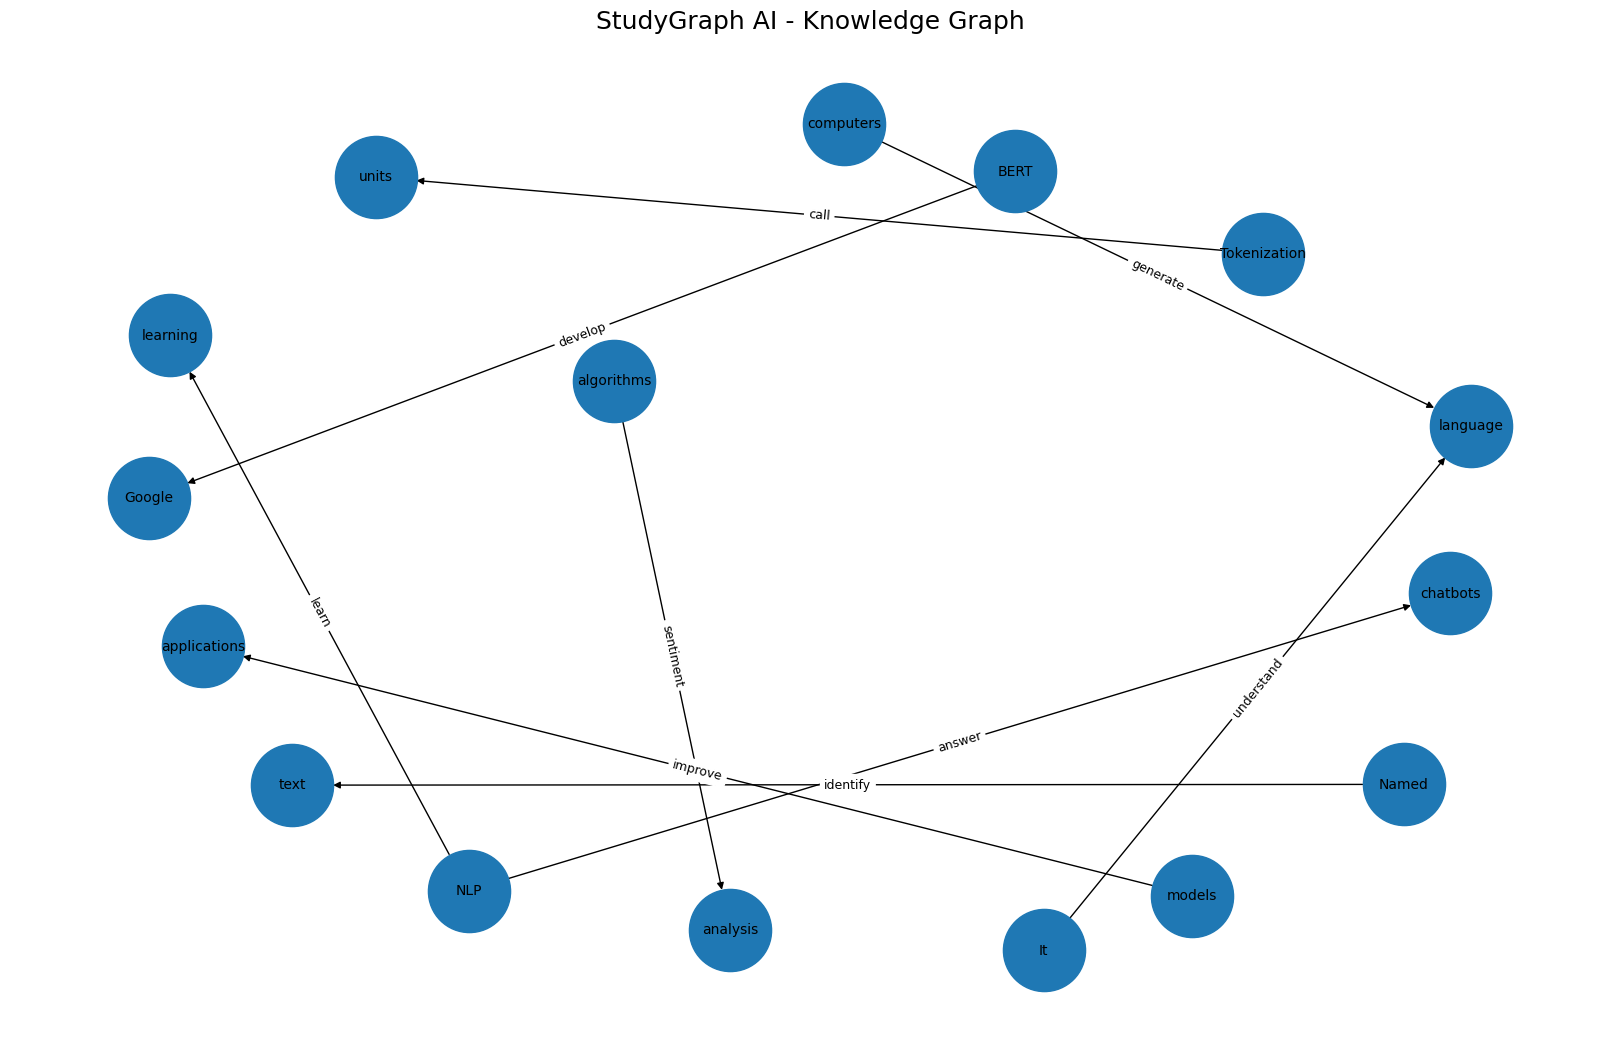

In [11]:
plt.figure(figsize=(16, 10))

position = nx.spring_layout(
    knowledge_graph,
    seed=42,
    k=2
)

nx.draw(
    knowledge_graph,
    position,
    with_labels=True,
    node_size=3500,
    font_size=10,
    arrows=True
)

edge_labels = nx.get_edge_attributes(
    knowledge_graph,
    "relation"
)

nx.draw_networkx_edge_labels(
    knowledge_graph,
    position,
    edge_labels=edge_labels,
    font_size=9
)

plt.title(
    "StudyGraph AI - Knowledge Graph",
    fontsize=18
)

plt.axis("off")

plt.show()

In [12]:
def generate_questions(relationships):

    questions = []

    for subject, relation, obj in relationships:

        question = (
            f"What is the relationship between "
            f"{subject} and {obj}?"
        )

        questions.append(question)

    return questions


questions = generate_questions(
    relationships
)

print("=" * 60)
print("AI GENERATED STUDY QUESTIONS")
print("=" * 60)

for i, question in enumerate(
    questions[:10],
    start=1
):

    print(
        f"{i}. {question}"
    )

AI GENERATED STUDY QUESTIONS
1. What is the relationship between computers and language?
2. What is the relationship between NLP and learning?
3. What is the relationship between Tokenization and units?
4. What is the relationship between Named and text?
5. What is the relationship between algorithms and analysis?
6. What is the relationship between models and applications?
7. What is the relationship between BERT and Google?
8. What is the relationship between It and language?
9. What is the relationship between NLP and chatbots?


In [13]:
def generate_study_questions(text):

    doc = nlp(text)

    questions = []

    for sentence in doc.sents:

        entities = list(sentence.ents)

        if entities:

            entity = entities[0]

            question = sentence.text.replace(
                entity.text,
                "What"
            )

            question = question.strip()

            if question.endswith("."):
                question = question[:-1]

            question += "?"

            questions.append(question)

    return questions


study_questions = generate_study_questions(
    study_text
)

print("GENERATED QUESTIONS\n")

for i, question in enumerate(
    study_questions[:10],
    start=1
):

    print(
        f"{i}. {question}"
    )

GENERATED QUESTIONS

1. Natural Language Processing is a branch of What that
allows computers to understand, interpret and generate human language?
2. What combines computational linguistics with machine learning and deep
learning techniques?
3. Named Entity What identifies entities such as people,
organizations, locations and dates from text?
4. Machine learning algorithms are widely used in What for text classification,
sentiment analysis and spam detection?
5. Deep learning models such as What and Transformers
have significantly improved NLP applications?
6. What is a transformer-based language model developed by Google?
7. What is used in applications such as chatbots, machine translation,
question answering, text summarization and sentiment analysis?


In [14]:
def search_notes(text, query):

    sentences = sent_tokenize(text)

    results = []

    for sentence in sentences:

        if query.lower() in sentence.lower():

            results.append(sentence)

    return results


query = input(
    "Enter a concept to search: "
)

results = search_notes(
    study_text,
    query
)

print("\nSEARCH RESULTS\n")

if results:

    for i, result in enumerate(
        results,
        start=1
    ):

        print(
            f"{i}. {result}"
        )

else:

    print(
        "No information found."
    )

Enter a concept to search: BERT

SEARCH RESULTS

1. BERT is a transformer-based language model developed by Google.


In [15]:
from sklearn.metrics.pairwise import cosine_similarity


def semantic_search(text, query, top_n=3):

    sentences = sent_tokenize(text)

    documents = sentences + [query]

    vectorizer = TfidfVectorizer(
        stop_words="english"
    )

    matrix = vectorizer.fit_transform(
        documents
    )

    similarities = cosine_similarity(
        matrix[-1],
        matrix[:-1]
    ).flatten()

    ranked_indices = similarities.argsort()[::-1]

    results = []

    for index in ranked_indices[:top_n]:

        results.append(
            (
                sentences[index],
                similarities[index]
            )
        )

    return results


query = input(
    "Ask/Search something about your notes: "
)

results = semantic_search(
    study_text,
    query
)

print("\nMOST RELEVANT CONTENT\n")

for sentence, score in results:

    print(
        f"Similarity: {score:.3f}"
    )

    print(sentence)

    print("-" * 60)

Ask/Search something about your notes: Which models understand language?

MOST RELEVANT CONTENT

Similarity: 0.343
It uses bidirectional contextual representations to understand language.
------------------------------------------------------------
Similarity: 0.316

Natural Language Processing is a branch of Artificial Intelligence that
allows computers to understand, interpret and generate human language.
------------------------------------------------------------
Similarity: 0.182
Deep learning models such as Recurrent Neural Networks and Transformers
have significantly improved NLP applications.
------------------------------------------------------------


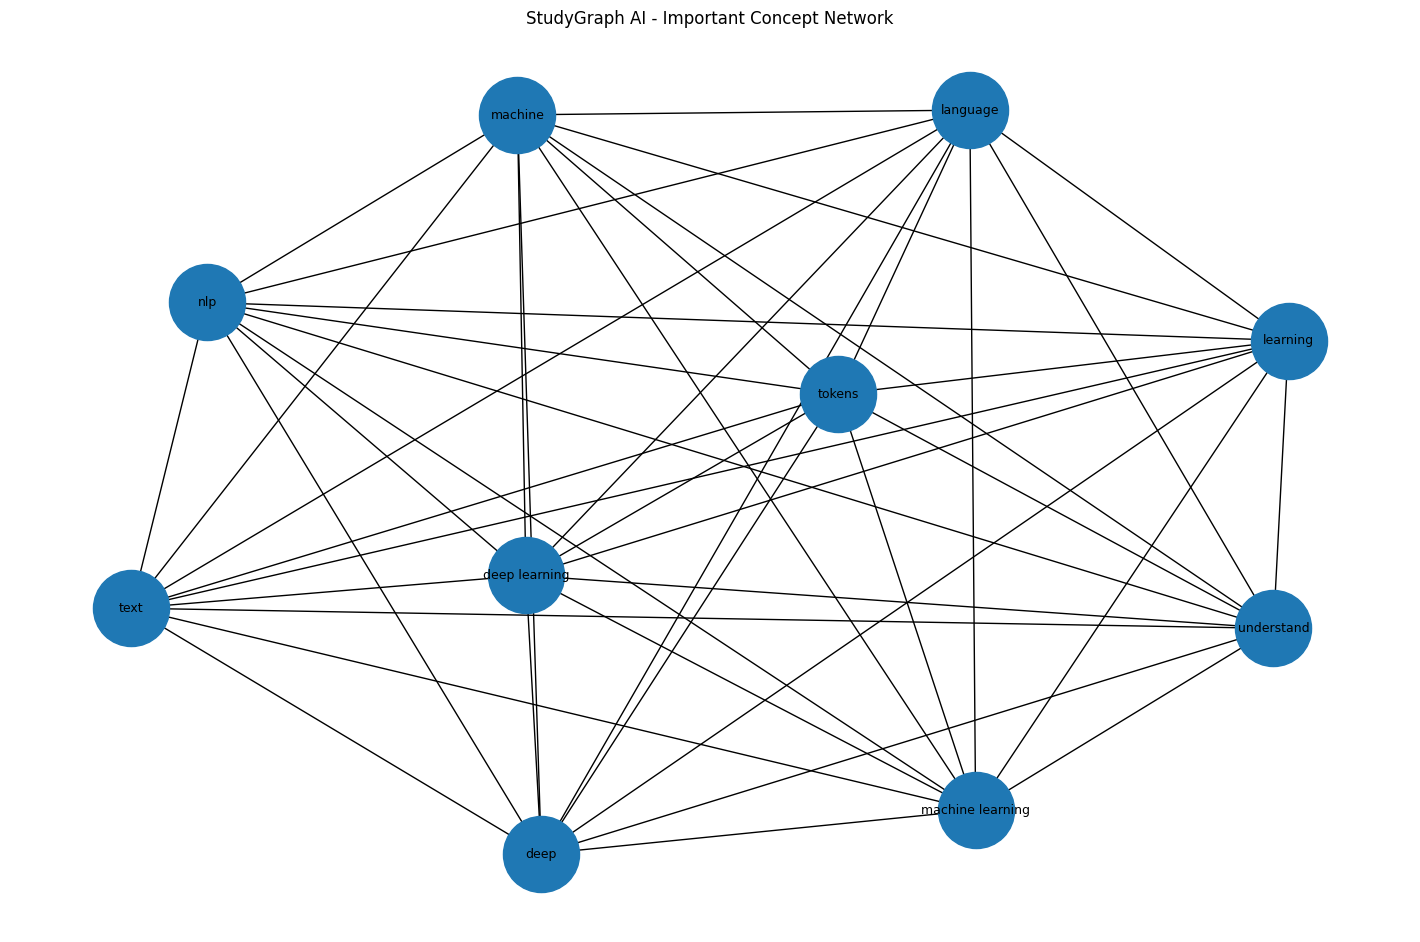

In [16]:
keyword_names = [
    keyword
    for keyword, score in keywords[:10]
]

keyword_graph = nx.Graph()

for keyword in keyword_names:

    keyword_graph.add_node(keyword)


for i in range(
    len(keyword_names)
):

    for j in range(
        i + 1,
        len(keyword_names)
    ):

        word1 = keyword_names[i]
        word2 = keyword_names[j]

        if (
            word1 in study_text.lower()
            and word2 in study_text.lower()
        ):

            keyword_graph.add_edge(
                word1,
                word2
            )


plt.figure(
    figsize=(14, 9)
)

position = nx.spring_layout(
    keyword_graph,
    seed=42
)

nx.draw(
    keyword_graph,
    position,
    with_labels=True,
    node_size=3000,
    font_size=9
)

plt.title(
    "StudyGraph AI - Important Concept Network"
)

plt.axis("off")

plt.show()

In [17]:
def studygraph_analysis(text):

    print(
        "=" * 70
    )

    print(
        "STUDYGRAPH AI"
    )

    print(
        "Intelligent Study Notes Analyzer"
    )

    print(
        "=" * 70
    )

    print(
        "\n1. AUTOMATIC SUMMARY\n"
    )

    print(
        summarize_text(text)
    )

    print(
        "\n2. IMPORTANT CONCEPTS\n"
    )

    keywords = extract_keywords(
        text,
        10
    )

    for keyword, score in keywords:

        print(
            f"{keyword:25} "
            f"{score:.3f}"
        )

    print(
        "\n3. NAMED ENTITIES\n"
    )

    entities = extract_entities(
        text
    )

    if entities:

        for entity, label in entities:

            print(
                entity,
                "->",
                label
            )

    else:

        print(
            "No named entities found."
        )

    print(
        "\n4. RELATIONSHIPS\n"
    )

    relationships = extract_relationships(
        text
    )

    if relationships:

        for subject, relation, obj in relationships:

            print(
                f"{subject} "
                f"--[{relation}]--> "
                f"{obj}"
            )

    else:

        print(
            "No relationships extracted."
        )

    print(
        "\n5. GENERATED QUESTIONS\n"
    )

    questions = generate_questions(
        relationships
    )

    for i, question in enumerate(
        questions[:5],
        1
    ):

        print(
            f"{i}. {question}"
        )

    print(
        "\n"
        + "=" * 70
    )

    print(
        "Analysis completed successfully!"
    )


studygraph_analysis(
    study_text
)

STUDYGRAPH AI
Intelligent Study Notes Analyzer

1. AUTOMATIC SUMMARY

Machine learning algorithms are widely used in NLP for text classification, sentiment analysis and spam detection. Deep learning models such as Recurrent Neural Networks and Transformers have significantly improved NLP applications. NLP is used in applications such as chatbots, machine translation, question answering, text summarization and sentiment analysis.

2. IMPORTANT CONCEPTS

language                  0.740
learning                  0.717
text                      0.627
nlp                       0.617
tokens                    0.554
machine                   0.524
understand                0.435
deep                      0.411
deep learning             0.411
machine learning          0.409

3. NAMED ENTITIES

Artificial Intelligence -> ORG
NLP -> ORG
Recognition -> ORG
NLP -> ORG
Recurrent Neural Networks -> ORG
NLP -> ORG
BERT -> ORG
Google -> ORG
NLP -> ORG

4. RELATIONSHIPS

computers --[generate]--> langu

In [20]:
from google.colab import files


uploaded = files.upload()


for filename in uploaded.keys():

    with open(
        filename,
        "r",
        encoding="utf-8"
    ) as file:

        uploaded_text = file.read()


print(
    "File loaded successfully!"
)

print(
    "\nCharacters:",
    len(uploaded_text)
)

print(
    "\nPreview:\n"
)

print(
    uploaded_text[:1000]
)

Saving nlp_study_notes.txt to nlp_study_notes.txt
File loaded successfully!

Characters: 6592

Preview:

NATURAL LANGUAGE PROCESSING AND TRANSFORMERS — STUDY NOTES

Natural Language Processing (NLP)

Natural Language Processing is a branch of Artificial Intelligence
concerned with enabling computers to process, understand, interpret, and
generate human language. Human language contains ambiguity, context,
grammatical structure, and different meanings, which makes automatic
language processing challenging. NLP combines ideas from computer
science, linguistics, machine learning, and deep learning.

Common NLP applications include machine translation, chatbots, question
answering, sentiment analysis, information retrieval, text
summarization, spam detection, and named entity recognition.

Text Preprocessing

Text preprocessing converts raw textual data into a form that can be
analyzed by NLP algorithms. Tokenization divides text into smaller units
called tokens. Tokens may represent words

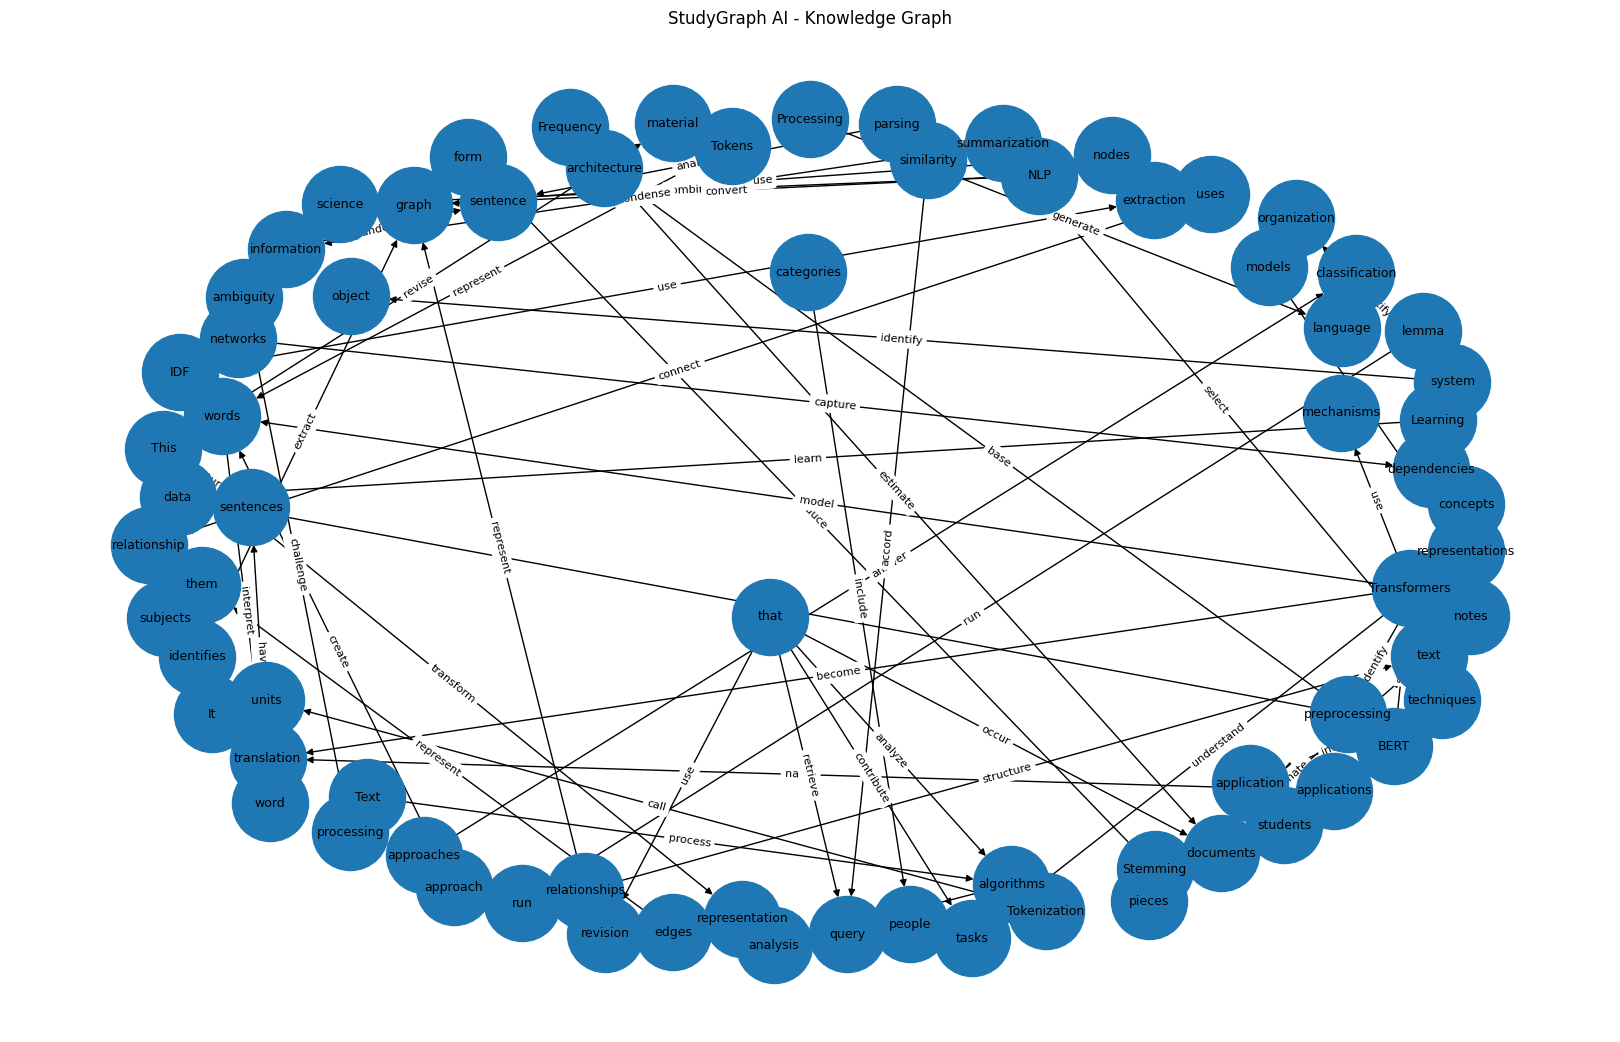

In [21]:
uploaded_relationships = extract_relationships(
    uploaded_text
)

uploaded_graph = create_knowledge_graph(
    uploaded_relationships
)

plt.figure(
    figsize=(16, 10)
)

position = nx.spring_layout(
    uploaded_graph,
    seed=42,
    k=2
)

nx.draw(
    uploaded_graph,
    position,
    with_labels=True,
    node_size=3000,
    font_size=9,
    arrows=True
)

edge_labels = nx.get_edge_attributes(
    uploaded_graph,
    "relation"
)

nx.draw_networkx_edge_labels(
    uploaded_graph,
    position,
    edge_labels=edge_labels,
    font_size=8
)

plt.title(
    "StudyGraph AI - Knowledge Graph"
)

plt.axis("off")

plt.show()